**Import necessary libraries**

In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data splitting and preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Model
from sklearn.naive_bayes import GaussianNB

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score
)

In [4]:
#load the dataset and inspect

df = pd.read_csv("insurance charges.csv")

# Display first five rows
print(df.head())

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Check data types
print(df.info())

# Check column names
print(df.columns)

   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520
Dataset Shape: (1338, 7)
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 94.5 KB
None
Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='st

**Create the target variable and split the dataset**

In [5]:
# Create binary target variable
df["high_charge"] = (df["charges"] > 16000).astype(int)

# Separate features and target
X = df.drop(columns=["charges", "high_charge"])
y = df["high_charge"]

# Split dataset into 70% training and 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

# Check target distribution
print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training set shape: (936, 6)
Testing set shape: (402, 6)

Training target distribution:
high_charge
0    694
1    242
Name: count, dtype: int64

Testing target distribution:
high_charge
0    298
1    104
Name: count, dtype: int64


In [6]:
#check and handle missing data 
# Check missing values
print("Missing values in training set:")
print(X_train.isnull().sum())

print("\nMissing values in testing set:")
print(X_test.isnull().sum())

Missing values in training set:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
dtype: int64

Missing values in testing set:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
dtype: int64


**Generate summary statistics for the continuous variables (age, BMI, charges).**

In [7]:
# Select continuous variables from training data
train_continuous = X_train[["age", "bmi"]].copy()

# Add original charges for exploration only
train_continuous["charges"] = df.loc[X_train.index, "charges"]

# Generate summary statistics
print(train_continuous.describe())

              age         bmi       charges
count  936.000000  936.000000    936.000000
mean    39.157051   30.642639  13256.109987
std     13.996253    6.016860  12073.982034
min     18.000000   16.815000   1121.873900
25%     26.750000   26.378750   4760.155950
50%     39.000000   30.447500   9289.083100
75%     51.000000   34.305000  16604.302645
max     64.000000   53.130000  63770.428010


**Visualize the distributions of the continuous features (age, bmi, and charges).**

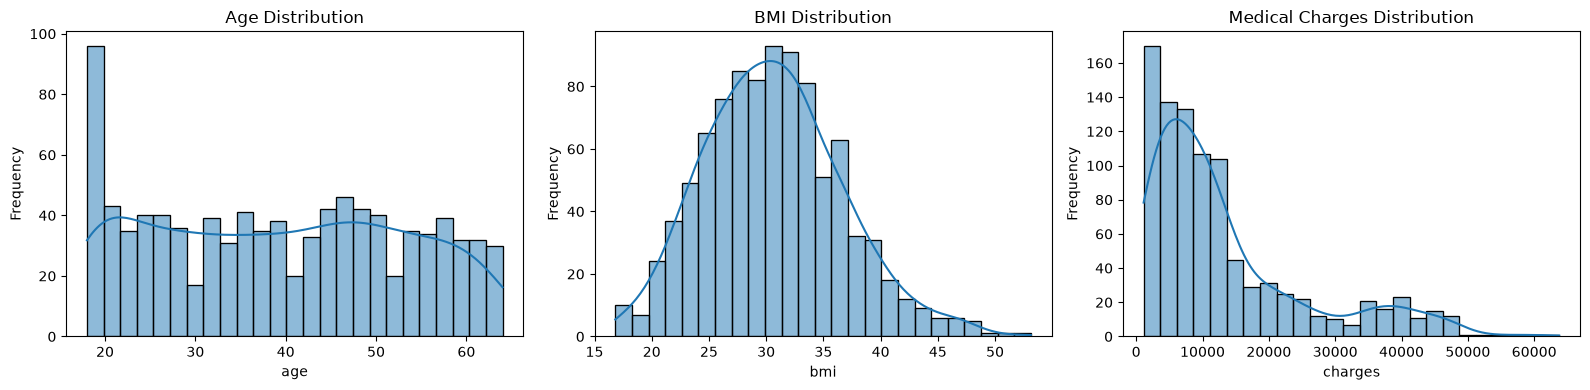

In [8]:
# Plot histograms
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

columns = ["age", "bmi", "charges"]
titles = [
    "Age Distribution",
    "BMI Distribution",
    "Medical Charges Distribution"
]

for i, col in enumerate(columns):
    sns.histplot(
        train_continuous[col],
        kde=True,
        bins=25,
        ax=axes[i]
    )
    axes[i].set_title(titles[i])
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

**Encode categorical variables**

In [9]:
from sklearn.impute import SimpleImputer

# Define feature groups
numerical_features = ["age", "bmi", "children"]
categorical_features = ["sex", "smoker", "region"]

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

**Train the Gaussian Naive Bayes model**

In [10]:
# Create Gaussian Naive Bayes pipeline
gnb_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", GaussianNB())
])

# Train the model
gnb_pipeline.fit(X_train, y_train)

# Predict test labels
y_pred = gnb_pipeline.predict(X_test)

print("Model trained successfully!")

Model trained successfully!


**Evaluate model performance**

In [11]:
# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("Gaussian Naive Bayes Performance")
print("--------------------------------")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

# Detailed classification report
print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Low Charges", "High Charges"],
    zero_division=0
))

Gaussian Naive Bayes Performance
--------------------------------
Accuracy:  0.9353
Precision: 0.9643
Recall:    0.7788
F1-score:  0.8617

Classification Report:
              precision    recall  f1-score   support

 Low Charges       0.93      0.99      0.96       298
High Charges       0.96      0.78      0.86       104

    accuracy                           0.94       402
   macro avg       0.95      0.88      0.91       402
weighted avg       0.94      0.94      0.93       402



**Generate the confusion matrix**

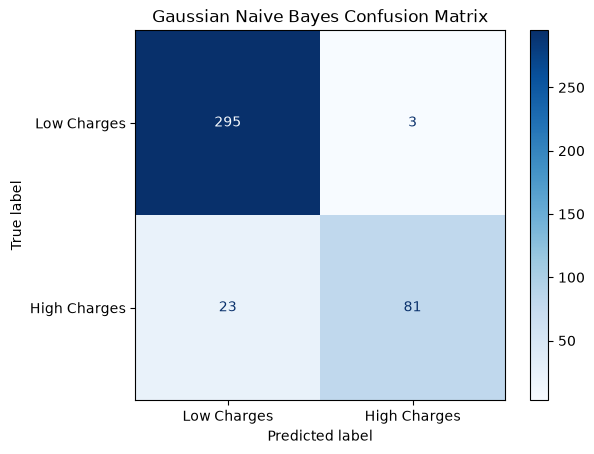

True Negatives: 295
False Positives: 3
False Negatives: 23
True Positives: 81


In [12]:
# Calculate confusion matrix
cm = confusion_matrix(y_test, y_pred)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Low Charges", "High Charges"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Gaussian Naive Bayes Confusion Matrix")
plt.show()

# Print confusion matrix values
tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

**Plot the ROC curve and calculate the AUC score.**

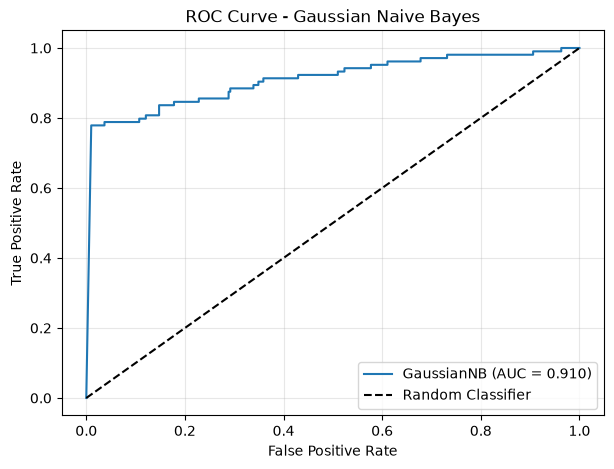

ROC-AUC Score: 0.9099


In [13]:
# Predict probabilities for high-charge class
y_prob = gnb_pipeline.predict_proba(X_test)[:, 1]

# Calculate ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# Calculate AUC
auc_score = roc_auc_score(y_test, y_prob)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"GaussianNB (AUC = {auc_score:.3f})"
)

plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Gaussian Naive Bayes")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

print(f"ROC-AUC Score: {auc_score:.4f}")

**Model optimization using feature scaling**

In [14]:
# Numerical preprocessing with scaling
scaled_numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Create scaled preprocessor
scaled_preprocessor = ColumnTransformer(
    transformers=[
        ("num", scaled_numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Create scaled Gaussian Naive Bayes pipeline
scaled_gnb_pipeline = Pipeline(steps=[
    ("preprocessor", scaled_preprocessor),
    ("model", GaussianNB())
])

# Train scaled model
scaled_gnb_pipeline.fit(X_train, y_train)

# Predict
y_pred_scaled = scaled_gnb_pipeline.predict(X_test)

# Calculate evaluation metrics
print("Scaled Gaussian Naive Bayes Performance")
print("--------------------------------------")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_scaled):.4f}")
print(f"Precision: {precision_score(y_test, y_pred_scaled, zero_division=0):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_scaled, zero_division=0):.4f}")
print(f"F1-score:  {f1_score(y_test, y_pred_scaled, zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_scaled,
    target_names=["Low Charges", "High Charges"],
    zero_division=0
))

Scaled Gaussian Naive Bayes Performance
--------------------------------------
Accuracy:  0.9353
Precision: 0.9643
Recall:    0.7788
F1-score:  0.8617

Classification Report:
              precision    recall  f1-score   support

 Low Charges       0.93      0.99      0.96       298
High Charges       0.96      0.78      0.86       104

    accuracy                           0.94       402
   macro avg       0.95      0.88      0.91       402
weighted avg       0.94      0.94      0.93       402



**Compare models before and after scaling**

In [15]:
# Calculate probabilities for scaled model
y_prob_scaled = scaled_gnb_pipeline.predict_proba(X_test)[:, 1]

# Create comparison DataFrame
comparison = pd.DataFrame({
    "Model": [
        "GaussianNB (Original)",
        "GaussianNB (Scaled)"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_scaled)
    ],
    "Precision": [
        precision_score(y_test, y_pred, zero_division=0),
        precision_score(y_test, y_pred_scaled, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred_scaled, zero_division=0)
    ],
    "F1-score": [
        f1_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred_scaled, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob),
        roc_auc_score(y_test, y_prob_scaled)
    ]
})

# Display comparison
print(comparison.round(4))

                   Model  Accuracy  Precision  Recall  F1-score  ROC-AUC
0  GaussianNB (Original)    0.9353     0.9643  0.7788    0.8617   0.9099
1    GaussianNB (Scaled)    0.9353     0.9643  0.7788    0.8617   0.9099


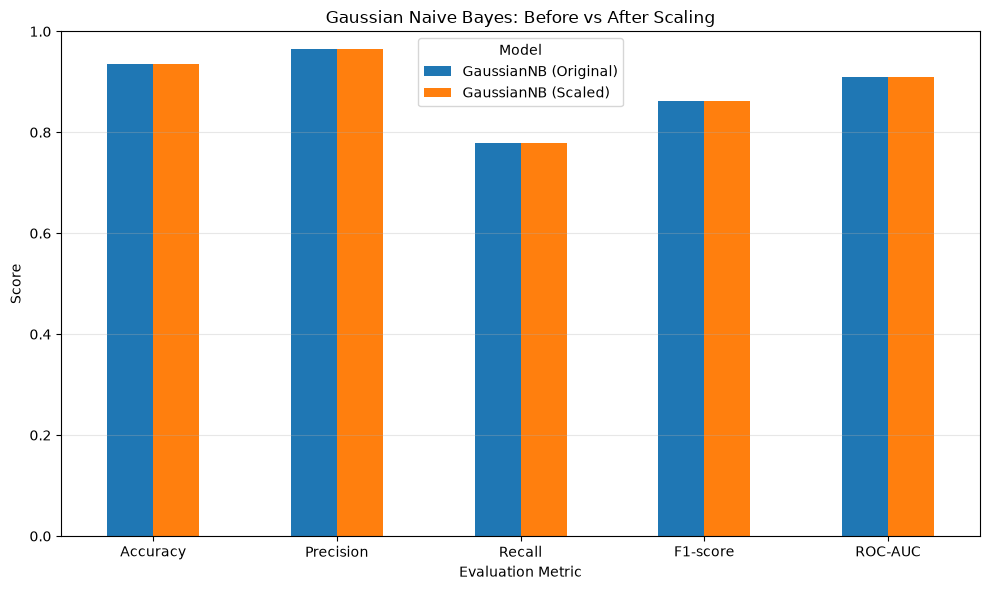

In [16]:
# Compare performance visually
comparison.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
].T.plot(kind="bar", figsize=(10, 6))

plt.title("Gaussian Naive Bayes: Before vs After Scaling")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Model")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

The original and scaled Gaussian Naive Bayes models produced identical evaluation results, with an accuracy of 93.53%, precision of 96.43%, recall of 77.88%, F1-score of 86.17%, and ROC-AUC of 90.99%.

Both models demonstrated strong classification performance, particularly in precision, indicating very few false positives. However, the lower recall suggests that approximately 22.12% of individuals with high medical charges were incorrectly classified as having low charges.